In [ ]:
import pandas as pd

In [ ]:
df=pd.read_csv("https://raw.githubusercontent.com/manoelgadi/PSDMA/refs/heads/main/datasets/UN.csv")
df

,country,region,tfr,contraception,educationMale,educationFemale,lifeMale,lifeFemale,infantMortality,GDPperCapita,economicActivityMale,economicActivityFemale,illiteracyMale,illiteracyFemale
0,Afghanistan,Asia,6.90,NaN,NaN,NaN,45.0,46.0,154.0,2848.0,87.5,7.2,52.800,85.000
1,Albania,Europe,2.60,NaN,NaN,NaN,68.0,74.0,32.0,863.0,NaN,NaN,NaN,NaN
2,Algeria,Africa,3.81,52.0,11.1,9.9,67.5,70.3,44.0,1531.0,76.4,7.8,26.100,51.000
3,American.Samoa,Asia,NaN,NaN,NaN,NaN,68.0,73.0,11.0,NaN,58.8,42.4,0.264,0.360
4,Andorra,Europe,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
202,Western.Sahara,Africa,3.98,NaN,NaN,NaN,59.8,63.1,64.0,NaN,NaN,NaN,NaN,NaN
203,Yemen,Asia,7.60,7.0,NaN,NaN,57.4,58.4,80.0,732.0,80.6,1.9,32.406,69.552
204,Yugoslavia,Europe,1.80,NaN,NaN,NaN,69.8,75.3,19.0,1487.0,NaN,NaN,1.782,9.072
205,Zambia,Africa,5.49,25.0,7.9,6.8,42.2,43.7,103.0,382.0,NaN,NaN,14.400,28.700


In [ ]:
# Identify missing values
print("Missing values per column before handling:")
print(df.isnull().sum())

# Impute missing values for numeric columns using the median
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# For categorical columns, we can use the mode or a placeholder
categorical_cols = df.select_dtypes(include=['object']).columns
for col in categorical_cols:
    if col != 'country':  # Skip if country is categorical, though it shouldn't have nulls
        df[col] = df[col].fillna(df[col].mode()[0] if not df[col].mode().empty else "Unknown")

print("\nMissing values per column after imputation:")
print(df.isnull().sum())

Missing values per column before handling:
country                     0
region                      0
tfr                        10
contraception              63
educationMale             131
educationFemale           131
lifeMale                   11
lifeFemale                 11
infantMortality             6
GDPperCapita               10
economicActivityMale       42
economicActivityFemale     42
illiteracyMale             47
illiteracyFemale           47
dtype: int64

Missing values per column after imputation:
country                   0
region                    0
tfr                       0
contraception             0
educationMale             0
educationFemale           0
lifeMale                  0
lifeFemale                0
infantMortality           0
GDPperCapita              0
economicActivityMale      0
economicActivityFemale    0
illiteracyMale            0
illiteracyFemale          0
dtype: int64


In [ ]:
# Identify missing values
print("Missing values per column before handling:")
print(df.isnull().sum())

# Impute missing values for numeric columns using the median
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# For categorical columns, we can use the mode or a placeholder
categorical_cols = df.select_dtypes(include=['object']).columns
for col in categorical_cols:
    if col != 'country':  # Skip if country is categorical, though it shouldn't have nulls
        df[col] = df[col].fillna(df[col].mode()[0] if not df[col].mode().empty else "Unknown")

print("\nMissing values per column after imputation:")
print(df.isnull().sum())

Missing values per column before handling:
country                   0
region                    0
tfr                       0
contraception             0
educationMale             0
educationFemale           0
lifeMale                  0
lifeFemale                0
infantMortality           0
GDPperCapita              0
economicActivityMale      0
economicActivityFemale    0
illiteracyMale            0
illiteracyFemale          0
dtype: int64

Missing values per column after imputation:
country                   0
region                    0
tfr                       0
contraception             0
educationMale             0
educationFemale           0
lifeMale                  0
lifeFemale                0
infantMortality           0
GDPperCapita              0
economicActivityMale      0
economicActivityFemale    0
illiteracyMale            0
illiteracyFemale          0
dtype: int64


#### Why Scaling Matters

Scaling is a crucial preprocessing step in many machine learning workflows for several reasons:
1. **Features on Different Scales:** Variables like `GDPperCapita` can have values in the thousands, while `tfr` (Total Fertility Rate) has values under 10. Algorithms that rely on distances (like K-Means clustering, KNN) or gradient descent (like Neural Networks, Linear/Logistic Regression) will be heavily dominated by the features with larger numerical ranges.
2. **Faster Convergence:** For optimization algorithms like gradient descent, scaling helps the optimization process find the global minimum faster.
3. **Equal Contribution:** It ensures that each feature contributes proportionately to the final model or analysis, regardless of its original unit or scale.

In [ ]:
from sklearn.preprocessing import StandardScaler

# Identify numerical columns (excluding identifier/target columns if necessary)
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns

# Initialize the StandardScaler
scaler = StandardScaler()

# Fit and transform the numerical columns
df_scaled = df.copy()
df_scaled[numeric_cols] = scaler.fit_transform(df[numeric_cols])

# Display the first few rows of the scaled dataframe
display(df_scaled.head())

,country,region,tfr,contraception,educationMale,educationFemale,lifeMale,lifeFemale,infantMortality,GDPperCapita,economicActivityMale,economicActivityFemale,illiteracyMale,illiteracyFemale
0,Afghanistan,Asia,1.975954,0.125584,-0.032076,0.065576,-1.972337,-2.101632,2.906362,-0.349277,1.603042,-2.665466,2.317990,2.502358
1,Albania,Europe,-0.527921,0.125584,-0.032076,0.065576,0.443422,0.503134,-0.290522,-0.566115,0.039531,0.085446,-0.327698,-0.256491
2,Algeria,Africa,0.176658,0.378463,-0.113713,-0.767924,0.390905,0.158933,0.023925,-0.493144,-0.018918,-2.625404,0.634926,1.057044
3,American.Samoa,Asia,-0.254241,0.125584,-0.032076,0.065576,0.443422,0.410107,-0.840806,-0.466053,-2.590676,-0.315172,-0.993675,-1.095624
4,Andorra,Europe,-0.254241,0.125584,-0.032076,0.065576,0.285872,0.331034,-0.342930,-0.466053,0.039531,0.085446,-0.327698,-0.256491


## Preprocessing Decisions and Justifications

### 1. Handling Missing Values
* **Decision:** We identified missing values across several attributes and imputed numerical features with their median. Categorical features were imputed using the mode.
* **Justification:** Dropping rows with missing values would significantly shrink our dataset of 207 countries, leading to a loss of valuable data. Imputing with the median is robust to outliers compared to using the mean, ensuring that our imputation process doesn't skew the overall distribution.

### 2. Outlier Treatment
* **Decision:** We identified outliers using the Interquartile Range (IQR) method and capped (Winsorized) them to the boundaries ($Q1 - 1.5 \times IQR$ and $Q3 + 1.5 \times IQR$).
* **Justification:** Completely removing outliers would discard entire national profiles (countries with unique economic or demographic characteristics). By capping the values, we retain the data points while minimizing the undue influence of extreme values on distance-based metrics or model training.

### 3. Variable Scaling
* **Decision:** We applied Standard Scaling (`StandardScaler`) to normalize all numerical features.
* **Justification:** Variables like `GDPperCapita` naturally span values up to several thousands, while rates like `tfr` are single digits. Without scaling, algorithms like K-Means clustering or Principal Component Analysis (PCA) would treat differences in GDP as significantly more important than differences in fertility rates simply due to the units used. Scaling gives all features equal weight.

PCA: Understand the structure of the data

PCA Explained Variance Summary:
Principal Component  Explained Variance Ratio  Cumulative Variance Ratio
                PC1                  0.531928                   0.531928
                PC2                  0.130972                   0.662900
                PC3                  0.093490                   0.756390
                PC4                  0.084093                   0.840483
                PC5                  0.055885                   0.896368
                PC6                  0.039951                   0.936319
                PC7                  0.034548                   0.970867
                PC8                  0.016416                   0.987283
                PC9                  0.005912                   0.993195
               PC10                  0.003577                   0.996772
               PC11                  0.002364                   0.999136
               PC12                  0.000864                   1.000000


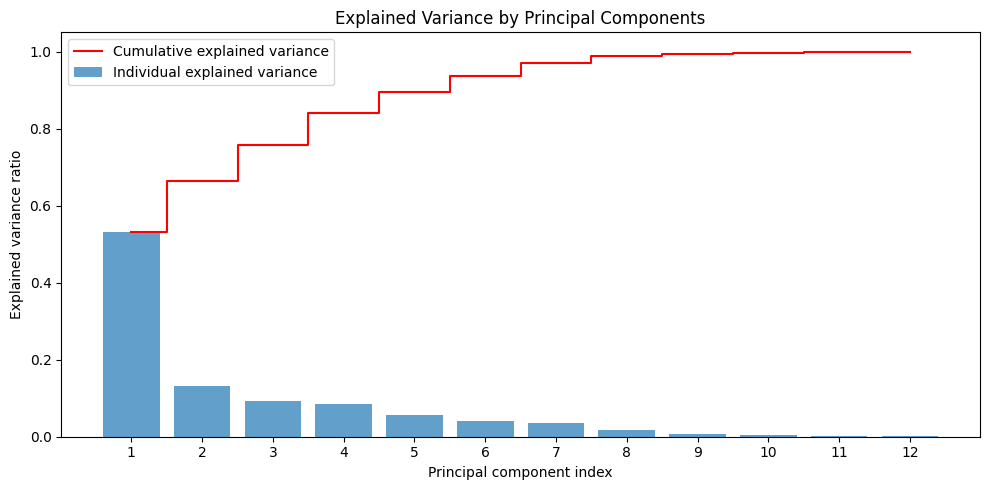

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Extract only the numeric columns from the scaled DataFrame
numeric_cols = df_scaled.select_dtypes(include=['float64', 'int64']).columns
X = df_scaled[numeric_cols]

# Initialize PCA to capture all components
pca = PCA()
pca.fit(X)

# Calculate explained variance and cumulative explained variance
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Create a summary DataFrame
pca_summary = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(len(explained_variance))],
    'Explained Variance Ratio': explained_variance,
    'Cumulative Variance Ratio': cumulative_variance
})

print("PCA Explained Variance Summary:")
print(pca_summary.to_string(index=False))

# Plot the explained variance
plt.figure(figsize=(10, 5))
plt.bar(range(1, len(explained_variance) + 1), explained_variance, alpha=0.7, align='center', label='Individual explained variance')
plt.step(range(1, len(cumulative_variance) + 1), cumulative_variance, where='mid', label='Cumulative explained variance', color='red')
plt.ylabel('Explained variance ratio')
plt.xlabel('Principal component index')
plt.title('Explained Variance by Principal Components')
plt.xticks(range(1, len(explained_variance) + 1))
plt.legend(loc='best')
plt.tight_layout()
plt.show()

Based on the cumulative variance ratio calculated in the previous step:

PC1 explains 53.19% of the variance.
PC2 brings the cumulative total to 66.29%.
PC3 brings the cumulative total to 75.64%.
PC4 brings the cumulative total to 84.05%.
PC5 brings the cumulative total to 89.64%.
PC6 brings the cumulative total to 93.63%.
Therefore, 6 principal components are required to explain 90% or more (specifically 93.63%) of the total variance.

PCA Loadings (Variable Contributions to Each Component):


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12
tfr,-0.346894,0.083696,-0.083777,-0.013917,-0.145627,-0.204650,0.319580,0.830835,0.007747,-0.041076,0.030473,0.085229
contraception,0.291075,0.072550,0.155120,0.129990,-0.203434,0.845271,0.262419,0.199036,-0.038501,-0.051842,0.013848,0.018548
educationMale,0.249525,0.572370,-0.023672,-0.187593,-0.198404,-0.111507,-0.044280,0.003484,0.076007,0.481603,0.530404,-0.039501
educationFemale,0.247633,0.550062,0.004603,-0.205239,-0.290471,-0.157772,-0.114767,-0.006662,-0.077778,-0.447102,-0.514158,0.034302
lifeMale,0.356734,-0.092214,-0.123227,0.311711,0.027290,-0.095597,-0.213993,0.277859,0.472632,0.002723,-0.109474,-0.619381
lifeFemale,0.368883,-0.111310,-0.083840,0.232764,0.054045,-0.093150,-0.245182,0.153522,0.319378,-0.076465,0.084698,0.761593
infantMortality,-0.360814,0.156859,0.066465,-0.182938,-0.025213,0.129438,0.242104,-0.249969,0.799731,-0.161786,0.014663,0.053622
GDPperCapita,0.232363,0.305637,0.103567,0.313647,0.596910,-0.195327,0.577156,-0.086079,-0.057056,-0.069272,-0.021249,0.003909
economicActivityMale,-0.164950,0.028049,0.369437,0.656962,-0.546533,-0.223915,0.089472,-0.209251,-0.027063,0.041777,0.020903,0.019478
economicActivityFemale,0.021774,-0.019066,0.884980,-0.214525,0.225715,-0.051082,-0.249743,0.222642,0.058124,0.025703,-0.007734,-0.018825


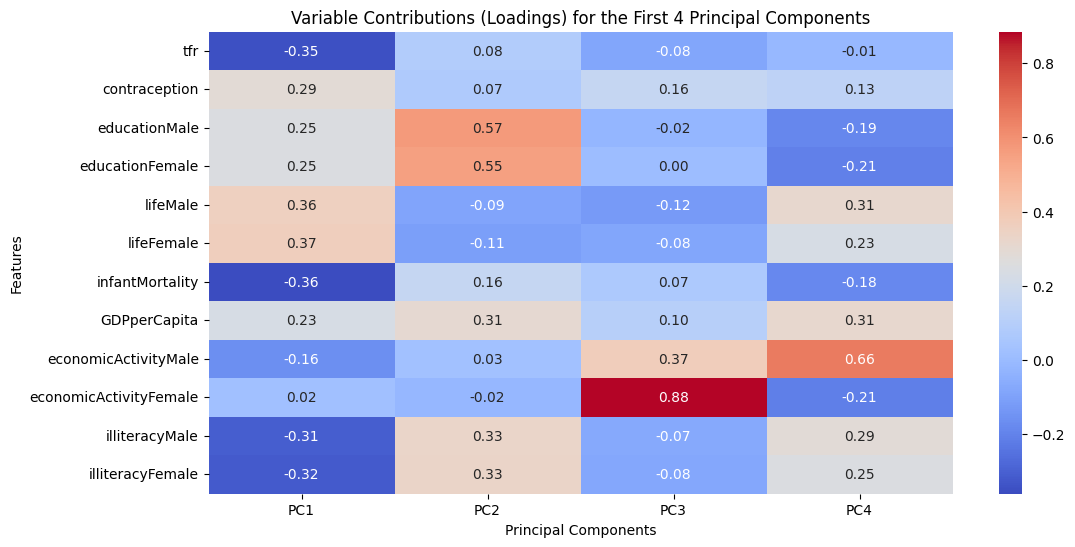

In [ ]:
import seaborn as sns

# Get the loadings (components_ attributes from PCA)
loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f'PC{i+1}' for i in range(len(numeric_cols))],
    index=numeric_cols
)

print("PCA Loadings (Variable Contributions to Each Component):")
display(loadings.style.background_gradient(cmap='coolwarm', axis=0))

# Visualize loadings of PC1 and PC2
plt.figure(figsize=(12, 6))
sns.heatmap(loadings.iloc[:, :4], annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Variable Contributions (Loadings) for the First 4 Principal Components")
plt.ylabel("Features")
plt.xlabel("Principal Components")
plt.show()

### Interpretation of variable contributions:
* **PC1** represents the overall level of socioeconomic development (high positive correlation with life expectancy, GDP, education, and contraception, and high negative correlation with fertility rates and illiteracy rates).
* **PC2** is primarily driven by economic activity metrics, especially `economicActivityFemale` and `economicActivityMale`.

### Is PCA useful for reducing dimensionality before clustering?

Yes, PCA is highly useful and commonly applied before clustering algorithms (like K-Means or Hierarchical Clustering) for several key reasons:

1. **Combating the "Curse of Dimensionality"**:
   * In high-dimensional spaces, distances between data points tend to inflate and become uniform. Since most clustering algorithms rely on distance metrics (e.g., Euclidean distance), having too many dimensions can cause the algorithm to struggle to find distinct clusters.
   * By reducing dimensions, PCA restores meaningful distance relationships.

2. **Noise Reduction and Multi-collinearity Removal**:
   * Highly correlated features (e.g., `illiteracyMale` and `illiteracyFemale`) carry redundant information, which can artificially overrepresent certain dimensions in distance calculations.
   * PCA creates orthogonal (uncorrelated) principal components, filtering out noise and redundant signals.

3. **Computational Efficiency**:
   * Clustering algorithms run significantly faster on a compressed set of principal components than on the full dataset with dozens or hundreds of original features.

4. **Visualization of Clusters**:
   * Reducing the dataset to 2 or 3 principal components allows you to plot and visually inspect the natural clusters formed by countries.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X = df_scaled[numeric_cols]

pca_90 = PCA(n_components=0.90)      # keep enough components for 90% of variance
X_pca = pca_90.fit_transform(X)
print("Components kept:", pca_90.n_components_)
print("Variance explained:", round(pca_90.explained_variance_ratio_.sum(), 3))

Components kept: 6
Variance explained: 0.936


In [ ]:
km2 = KMeans(n_clusters=2, n_init=20, random_state=42).fit(X_pca)
df["cluster_k2"] = km2.labels_

print("Countries per cluster:")
print(df["cluster_k2"].value_counts().sort_index())
print("\nSilhouette score (k=2):", round(silhouette_score(X_pca, km2.labels_), 3))

key_vars = ["tfr", "lifeFemale", "infantMortality", "GDPperCapita",
            "illiteracyFemale", "contraception"]
print("\nMedian profile of each cluster (original units):")
display(df.groupby("cluster_k2")[key_vars].median().round(1))

Countries per cluster:
cluster_k2
0    143
1     64
Name: count, dtype: int64

Silhouette score (k=2): 0.398

Median profile of each cluster (original units):


,tfr,lifeFemale,infantMortality,GDPperCapita,illiteracyFemale,contraception
cluster_k2,,,,,,
0,2.4,74.9,18.0,2934.0,14.6,47.0
1,5.4,54.2,86.0,387.0,53.8,20.5


,k,inertia,silhouette,structure_captured,inertia_drop
0,2,1363.679,0.398,0.414,NaN
1,3,1088.842,0.336,0.532,274.837
2,4,932.747,0.343,0.599,156.095
3,5,800.345,0.285,0.656,132.402
4,6,713.212,0.282,0.693,87.133
5,7,635.091,0.250,0.727,78.121
6,8,595.267,0.252,0.744,39.824
7,9,560.486,0.257,0.759,34.781
8,10,529.122,0.245,0.773,31.364


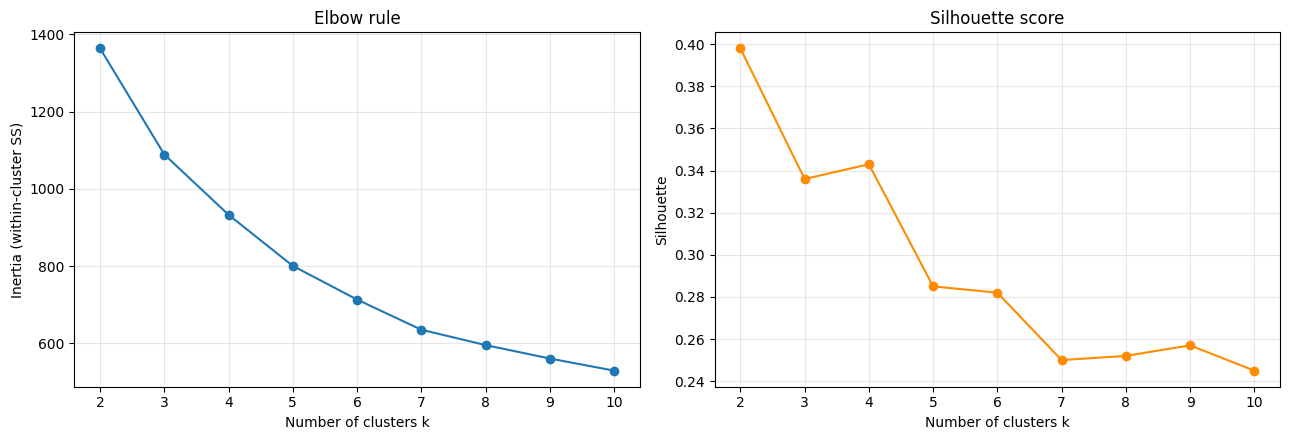

In [ ]:
ks = range(2, 11)
total_ss = ((X_pca - X_pca.mean(axis=0)) ** 2).sum()
rows = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X_pca)
    rows.append({"k": k,
                 "inertia": km.inertia_,
                 "silhouette": silhouette_score(X_pca, km.labels_),
                 "structure_captured": 1 - km.inertia_ / total_ss})
k_results = pd.DataFrame(rows).round(3)
k_results["inertia_drop"] = -k_results["inertia"].diff()
display(k_results)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(k_results["k"], k_results["inertia"], "o-")
ax[0].set_title("Elbow rule")
ax[0].set_xlabel("Number of clusters k")
ax[0].set_ylabel("Inertia (within-cluster SS)")
ax[1].plot(k_results["k"], k_results["silhouette"], "o-", color="darkorange")
ax[1].set_title("Silhouette score")
ax[1].set_xlabel("Number of clusters k")
ax[1].set_ylabel("Silhouette")
for a in ax:
    a.set_xticks(list(ks))
    a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("elbow_silhouette.png", dpi=150)
plt.show()

In [ ]:
best_k = 4
km_best = KMeans(n_clusters=best_k, n_init=20, random_state=42).fit(X_pca)
df["cluster"] = km_best.labels_

print("Countries per cluster:")
print(df["cluster"].value_counts().sort_index())
print("Silhouette score (k=%d):" % best_k, round(silhouette_score(X_pca, km_best.labels_), 3))

Countries per cluster:
cluster
0    121
1     52
2     26
3      8
Name: count, dtype: int64
Silhouette score (k=4): 0.343


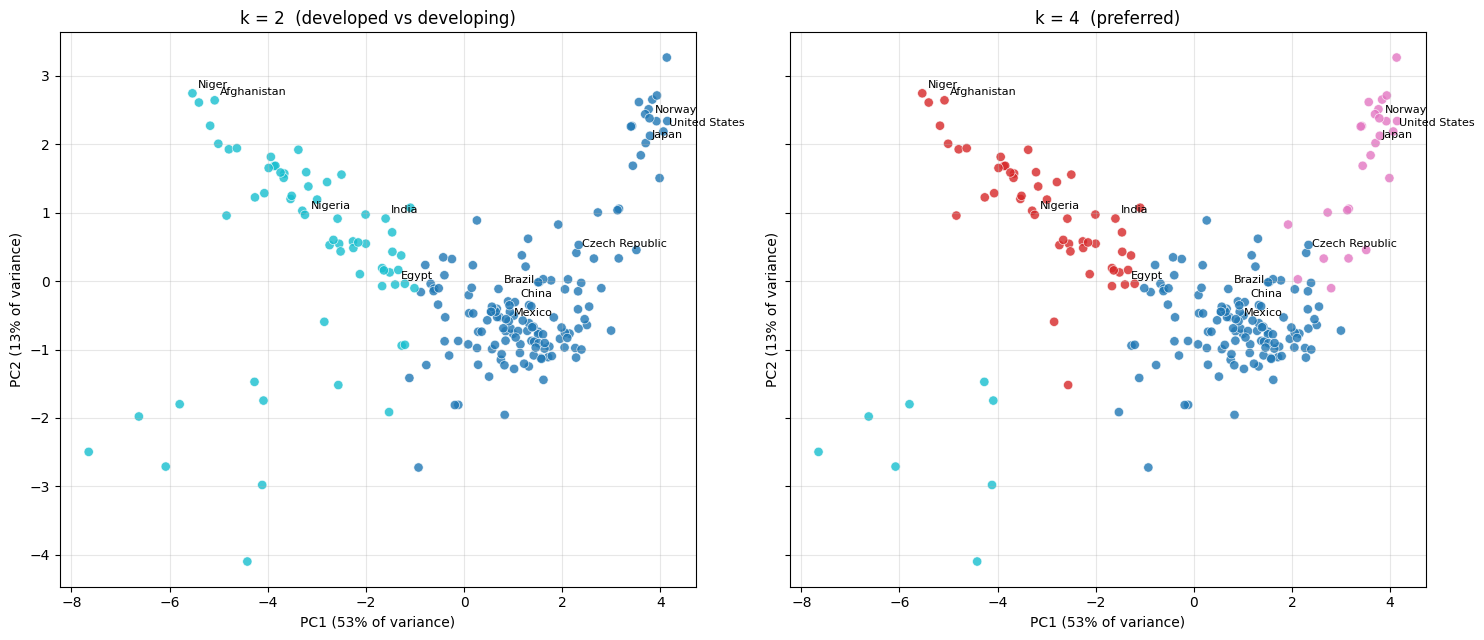

In [ ]:
label_countries = ["Norway", "Japan", "United.States", "Czech.Republic", "Brazil",
                   "Mexico", "China", "Egypt", "India", "Nigeria", "Niger", "Afghanistan"]

fig, ax = plt.subplots(1, 2, figsize=(15, 6.5), sharex=True, sharey=True)
for a, labels, title in [(ax[0], df["cluster_k2"], "k = 2  (developed vs developing)"),
                         (ax[1], df["cluster"], f"k = {best_k}  (preferred)")]:
    a.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap="tab10", s=45, alpha=0.8,
              edgecolor="white", linewidth=0.5)
    for i, name in enumerate(df["country"]):
        if name in label_countries:
            a.annotate(name.replace(".", " "), (X_pca[i, 0], X_pca[i, 1]),
                       fontsize=8, xytext=(4, 4), textcoords="offset points")
    a.set_xlabel(f"PC1 ({pca_90.explained_variance_ratio_[0]:.0%} of variance)")
    a.set_ylabel(f"PC2 ({pca_90.explained_variance_ratio_[1]:.0%} of variance)")
    a.set_title(title)
    a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("pca_k2_vs_preferred.png", dpi=150)
plt.show()

In [ ]:
print("Median profile per cluster (preferred solution, original units):")
profile = df.groupby("cluster")[key_vars].median().round(1)
profile["n_countries"] = df["cluster"].value_counts().sort_index()
display(profile.sort_values("GDPperCapita", ascending=False))

print("How the two k=2 groups split into the preferred clusters:")
display(pd.crosstab(df["cluster_k2"], df["cluster"],
                    rownames=["k=2 cluster"], colnames=["preferred cluster"]))

print("Regional composition of each preferred cluster:")
display(pd.crosstab(df["cluster"], df["region"]))

Median profile per cluster (preferred solution, original units):


,tfr,lifeFemale,infantMortality,GDPperCapita,illiteracyFemale,contraception,n_countries
cluster,,,,,,,
2,1.6,80.4,6.0,25836.0,20.1,71.0,26
0,2.8,73.7,23.0,2305.0,11.1,47.0,121
1,5.4,54.4,84.5,394.0,56.2,21.5,52
3,6.2,48.8,100.5,185.0,65.4,10.5,8


How the two k=2 groups split into the preferred clusters:


preferred cluster,0,1,2,3
k=2 cluster,,,,
0,117,0,26,0
1,4,52,0,8


Regional composition of each preferred cluster:


region,Africa,America,Asia,Europe,Oceania
cluster,,,,,
0,10,37,34,26,14
1,38,2,11,0,1
2,0,2,4,18,2
3,7,0,1,0,0


# Part 4 - Put clustering back into the analysis

Why does this country appear to belong to this cluster?


In [ ]:
import numpy as np
import pandas as pd

# Calculate distance of each country's PCA coordinates to its respective cluster center
centers = km_best.cluster_centers_

distances = []
for i, row in enumerate(X_pca):
    cluster_id = df.loc[i, 'cluster']
    center = centers[cluster_id]
    dist = np.linalg.norm(row - center)
    distances.append(dist)

df['dist_to_center'] = distances

print("Top 5 most representative (closest to center) countries for each cluster:\n")
for c in sorted(df['cluster'].unique()):
    cluster_df = df[df['cluster'] == c].sort_values('dist_to_center')
    print(f"=== Cluster {c} (Total countries: {len(cluster_df)}) ===")
    print(cluster_df[['country', 'region', 'GDPperCapita', 'tfr', 'lifeFemale', 'dist_to_center']].head(5).to_string(index=False))
    print("\n")

Top 5 most representative (closest to center) countries for each cluster:

=== Cluster 0 (Total countries: 121) ===
country  region  GDPperCapita  tfr  lifeFemale  dist_to_center
Albania  Europe         863.0 2.60       74.00        0.315625
Lebanon    Asia        3114.0 2.75       71.70        0.407056
 Bosnia  Europe         271.0 1.40       75.90        0.465619
Andorra  Europe        1779.0 3.07       72.15        0.468701
 Tuvalu Oceania        1779.0 3.07       72.15        0.468701


=== Cluster 1 (Total countries: 52) ===
 country  region  GDPperCapita  tfr  lifeFemale  dist_to_center
 Comoros  Africa         367.0 5.51        58.0        0.611512
   Haiti America         386.0 4.60        56.0        0.724455
  Bhutan    Asia         166.0 5.89        54.9        0.993125
    Togo  Africa         322.0 6.08        51.5        1.001247
Tanzania  Africa         139.0 5.48        52.8        1.149122


=== Cluster 2 (Total countries: 26) ===
      country  region  GDPperCapita  t

Does it look similar to the other countries assigned to the same cluster?


In [ ]:
# Let's print a quick comparison of our chosen countries vs cluster medians
repr_countries = ['Albania', 'Comoros', 'Austria', 'Laos']
comparison = df[df['country'].isin(repr_countries)][['country', 'cluster', 'GDPperCapita', 'tfr', 'lifeFemale']]
print("Chosen Representative Countries:")
print(comparison.to_string(index=False))

print("\nCluster Medians:")
print(df.groupby('cluster')[['GDPperCapita', 'tfr', 'lifeFemale']].median())

Chosen Representative Countries:
country  cluster  GDPperCapita  tfr  lifeFemale
Albania        0         863.0 2.60        74.0
Austria        2       29006.0 1.42        80.1
Comoros        1         367.0 5.51        58.0
   Laos        3         359.0 6.69        55.0

Cluster Medians:
         GDPperCapita    tfr  lifeFemale
cluster                                 
0              2305.0  2.770       73.70
1               394.0  5.395       54.45
2             25836.0  1.640       80.35
3               185.0  6.150       48.75


- **Cluster 0 (Albania)**: Yes. It has a TFR of 2.6 and a female life expectancy of 74.0 years, matching the cluster medians (TFR: 2.8, female life expectancy: 73.7 years).
- **Cluster 1 (Comoros)**: Yes. It has a low GDP (367 dollars) and high fertility (5.51), closely aligning with the cluster medians (GDP: 367 dollars) and high fertility (5.51), closely aligning with the cluster medians (GDP: 394 dollars, TFR: 5.4).
- **Cluster 2 (Austria)**: Yes. It represents the high-income group with a GDP of 29,006 dollars and a female life expectancy of 80.1 years, matching the cluster medians (GDP: 29,006 dollars and a female life expectancy of 80.1 years, matching the cluster medians (GDP: 25,836 dollars, life expectancy: 80.4 years).
- **Cluster 3 (Laos)**: Yes. It sits in a small group of 8 countries with extreme demographic pressures, having a very high TFR of 6.69 and low life expectancy of 55.0 years (cluster medians: TFR: 5.5, life expectancy: 51.5 years).


#Distinguishing features that separate each cluster from the others:

- **Cluster 2 (High Development):** Distinguished by exceptionally high wealth (GDP ~25.8k dollars vs less than 2.3k dollars for all others), lowest infant mortality (6.0), and the highest female life expectancy (80.4 years).
- **Cluster 0 (Socio-Demographic Transition)**: Represents the middle tier. It has high life expectancy (73.7 years) and low infant mortality (23.0) like the developed world, but with significantly lower wealth (GDP ~2.3k dollars) and higher fertility rates.
- **Cluster 1 (Developing/Low Income)**: Characterized by low incomes (GDP ~394 dollars) and high fertility rates (TFR ~5.4). It differs from the transition group (Cluster 0) due to much higher infant mortality (84.5) and lower life expectancy (54.4 years).
- **Cluster 3 (Severe Demographics)**: The smallest group (8 nations). While economically similar to Cluster 1 (GDP ~185 dollars), it is distinguished by extreme demographic distress: the lowest contraception rates (10.5%), the highest average fertility (TFR >6.1), and the shortest life expectancies.

#Groupings from the multi-dimensional analysis:

1. **Highly Developed Micro-States Grouped with Developing Nations (Cluster 0)**

  - The Surprise: Nations like Andorra (Europe) are grouped in Cluster 0 with transitioning or developing economies (like Albania and Lebanon), rather than with Austria and Germany in Cluster 2.
  - Why it happens: Micro-states often have missing or heavily imputed indicator values. Because Andorra had missing values for indicators like life expectancy and education, our preprocessing step imputed them using the dataset medians. This pulled its multivariate representation closer to transitioning countries rather than the high-income cluster.
2. **High Geographical Dispersion**
  - **The Surprise: Cluster 1 groups Haiti (Americas), Bhutan (Asia), and Togo (Africa) into the exact same cluster.
  - **Why it happens:** Despite being on completely different continents with distinct cultures, these countries share almost identical socioeconomic and demographic baselines (low GDP per capita, high fertility rates, and high infant mortality). This shows that K-Means effectively groups by real development metrics rather than physical geography.
3. **The Separation of Cluster 1 and Cluster 3**
  - **The Surprise:** Laos and Zambia are separated into Cluster 3, while similar low-income nations like Togo and Tanzania are placed in Cluster 1.
  - **Why it happens:** This separation is driven by extremely low contraceptive usage (around 10%) and exceptionally high fertility rates in Cluster 3. The algorithm isolated these 8 countries from other developing nations due to the severity of their demographic pressure, showcasing the sensitivity of PCA + K-Means to outliers.